In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
DATA_PATH = Path('../src/clean_data.csv')
DS1_PATH = Path('../src/ds1.csv')
DS2_PATH = Path('../src/ds2.csv')

FS = 360
CLASSES = ['N', 'S', 'V', 'F', 'Q']

In [3]:
df = pd.read_csv(DATA_PATH)

signal_columns = sorted(
    [c for c in df.columns if c.startswith('x_')],
    key=lambda c: int(c.split('_')[1])
)

ds1_df = pd.read_csv(DS1_PATH)
ds2_df = pd.read_csv(DS2_PATH)

assert len(df) == len(ds1_df) + len(ds2_df)
assert len(signal_columns) == 260

print('Cały zbiór:', df.shape)
print('DS1:', ds1_df.shape)
print('DS2:', ds2_df.shape)

Cały zbiór: (109451, 266)
DS1: (57549, 266)
DS2: (51902, 266)


In [5]:
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_n': df.isna().sum(),
    'missing_pct': 100 * df.isna().mean(),
    'unique_n': df.nunique(dropna=False)
})
summary.loc[['record_id', 'annotation_sample', 'type', 'anomaly', 'class', 'lead']]

,dtype,missing_n,missing_pct,unique_n
record_id,int64,0,0.0,48
annotation_sample,int64,0,0.0,100944
type,str,0,0.0,15
anomaly,int64,0,0.0,2
class,str,0,0.0,5
lead,str,0,0.0,2


### Sprawdzenie liczebności klas

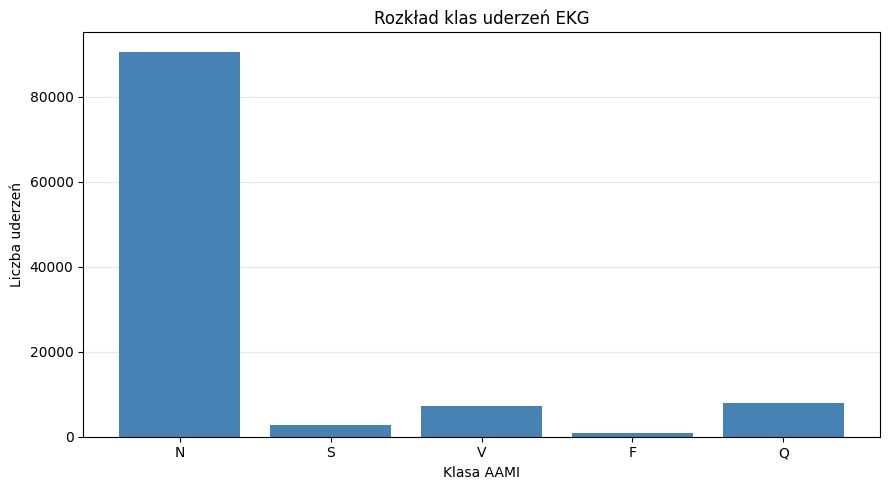

In [6]:
counts = df['class'].value_counts().reindex(CLASSES)

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    counts.index,
    counts.values,
    color='steelblue'
)

ax.set_xlabel('Klasa AAMI')
ax.set_ylabel('Liczba uderzeń')
ax.set_title('Rozkład klas uderzeń EKG')

ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [7]:
class_comparison = pd.DataFrame({
    'DS1': ds1_df['class'].value_counts(),
    'DS2': ds2_df['class'].value_counts()
}).reindex(CLASSES, fill_value=0)

display(class_comparison)

,DS1,DS2
class,,
N,48168,42425
S,999,1782
V,3813,3422
F,415,387
Q,4154,3886


In [8]:
class_comparison_pct = (
    class_comparison
    .div(class_comparison.sum(axis=0), axis=1)
    * 100
).round(2)

display(class_comparison_pct)

,DS1,DS2
class,,
N,83.70,81.74
S,1.74,3.43
V,6.63,6.59
F,0.72,0.75
Q,7.22,7.49


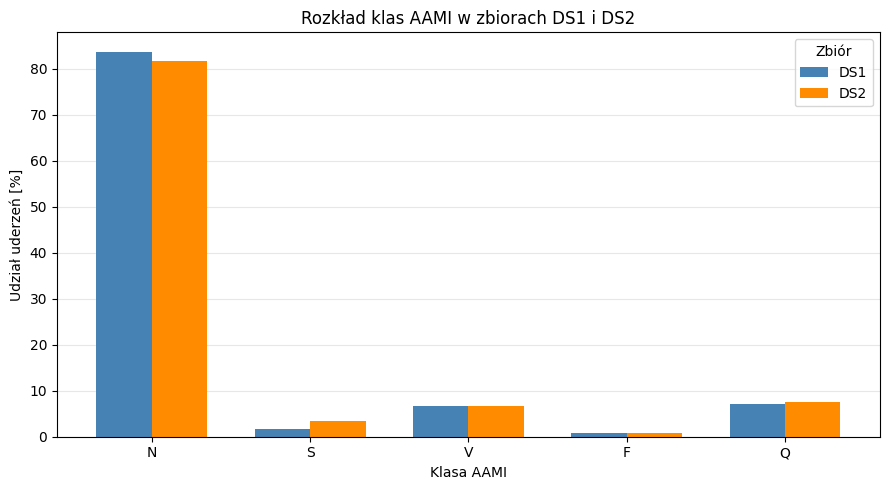

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

class_comparison_pct.plot(
    kind='bar',
    ax=ax,
    color=['steelblue', 'darkorange'],
    width=0.7
)

ax.set_title('Rozkład klas AAMI w zbiorach DS1 i DS2')
ax.set_xlabel('Klasa AAMI')
ax.set_ylabel('Udział uderzeń [%]')
ax.tick_params(axis='x', rotation=0)

ax.legend(title='Zbiór')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

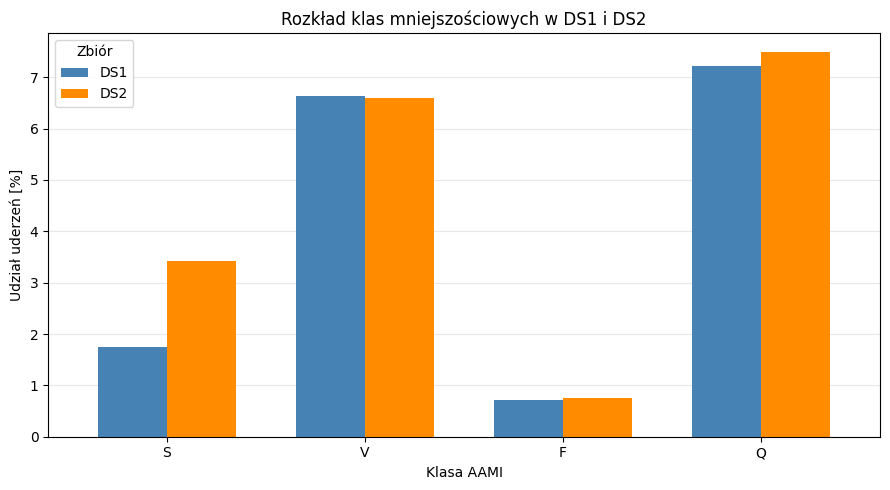

In [10]:
minority_classes = ['S', 'V', 'F', 'Q']

fig, ax = plt.subplots(figsize=(9, 5))

class_comparison_pct.loc[minority_classes].plot(
    kind='bar',
    ax=ax,
    color=['steelblue', 'darkorange'],
    width=0.7
)

ax.set_title('Rozkład klas mniejszościowych w DS1 i DS2')
ax.set_xlabel('Klasa AAMI')
ax.set_ylabel('Udział uderzeń [%]')
ax.tick_params(axis='x', rotation=0)

ax.legend(title='Zbiór')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
type_distribution = pd.DataFrame({
    'count': counts,
    'pct': round(counts / len(df) * 100, 2)
}).sort_values(
    by='count',
    ascending=False
)
display(type_distribution)

,count,pct
class,,
N,90593,82.77
Q,8040,7.35
V,7235,6.61
S,2781,2.54
F,802,0.73


### Sprawdzenie liczebności anomalia vs. normalny

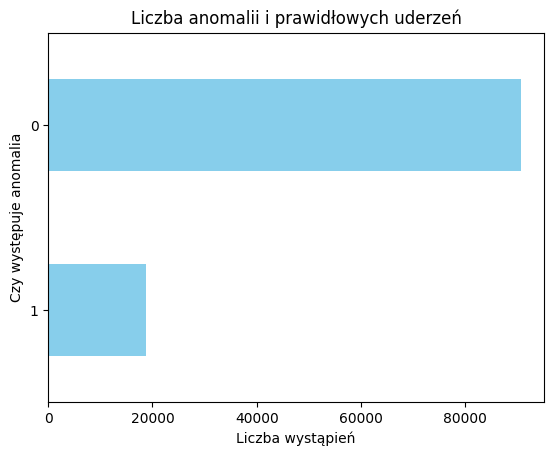

In [7]:
anomalies = df['anomaly'].value_counts().sort_values()

anomalies.plot(kind='barh', color='skyblue')
plt.ylabel('Czy występuje anomalia')
plt.xlabel('Liczba wystąpień')
plt.title('Liczba anomalii i prawidłowych uderzeń')
plt.show()

In [8]:
anomaly_pct = anomalies[1] / (anomalies[0]+anomalies[1]) * 100

print(f'Uderzenia anomalne stanowią {round(anomaly_pct,2)}% wszystkich uderzeń')

Uderzenia anomalne stanowią 17.23% wszystkich uderzeń


#### Sprawdzenie udziału uderzeń anomalnych per record_id

In [9]:
record_id_agg = (
    df.groupby('record_id')
    .agg(
        beats=('anomaly','size'),
        normal=('anomaly', lambda x: (x==0).sum()),
        anomaly=('anomaly', lambda x: (x==1).sum()),
    )
)
record_id_agg['anomaly_pct'] = round(record_id_agg['anomaly'] / record_id_agg['beats'] * 100, 2)

record_id_agg.sort_values('anomaly_pct', ascending=False)

,beats,normal,anomaly,anomaly_pct
record_id,,,,
107,2136,0,2136,100.00
102,2187,99,2088,95.47
104,2227,163,2064,92.68
217,2208,244,1964,88.95
232,1780,398,1382,77.64
208,2953,1585,1368,46.33
200,2600,1742,858,33.00
233,3077,2229,848,27.56
106,2027,1507,520,25.65


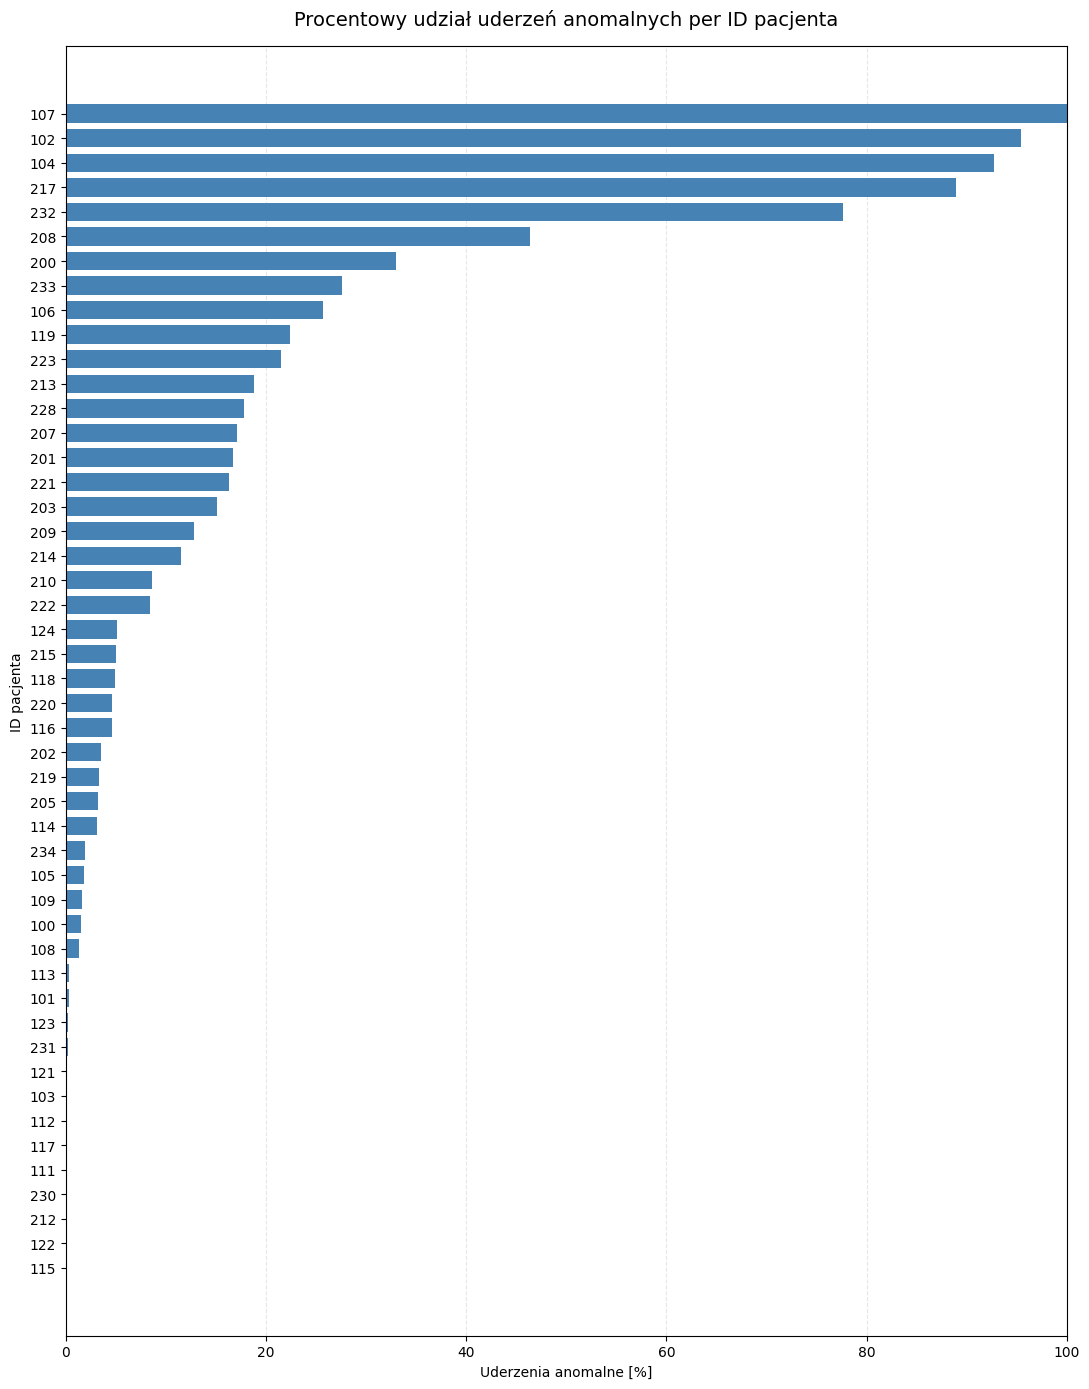

In [ ]:
plot_data = record_id_agg.sort_values(
    by='anomaly_pct',
    ascending=True
)

fig, ax = plt.subplots(figsize=(11,14))

ax.barh(
    plot_data.index.astype(str),
    plot_data['anomaly_pct'],
    color='steelblue',
    height=0.75
)

ax.set_title(
    'Procentowy udział uderzeń anomalnych per ID rekordu',
    fontsize=14,
    pad=15
)
ax.set_xlabel('Uderzenia anomalne [%]')
ax.set_ylabel('ID rekordu')

ax.set_xlim(0,100)
ax.grid(axis='x',linestyle='--',alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Sprawdzenie liczby rekordów dla których występują dane typy uderzeń

In [11]:
df['record_id'].nunique()

48

In [13]:
record_id_agg = (
    df.groupby('class')
    .agg(
        beats_count=('class', 'size'),
        record_id_count=('record_id','nunique')
    )
    .sort_values(
        by='beats_count',
        ascending=False
    )
)
record_id_agg

,beats_count,record_id_count
class,,
N,90593,47
Q,8040,9
V,7235,37
S,2781,32
F,802,17


In [14]:
record_class_counts = pd.crosstab(df['record_id'], df['class'])
record_class_counts

class,F,N,Q,S,V
record_id,,,,,
100,0,2237,0,33,1
101,0,1859,2,3,0
102,0,99,2084,0,4
103,0,2081,0,2,0
104,0,163,2062,0,2
105,0,2526,5,0,41
106,0,1507,0,0,520
107,0,0,2077,0,59
108,2,1739,0,4,17


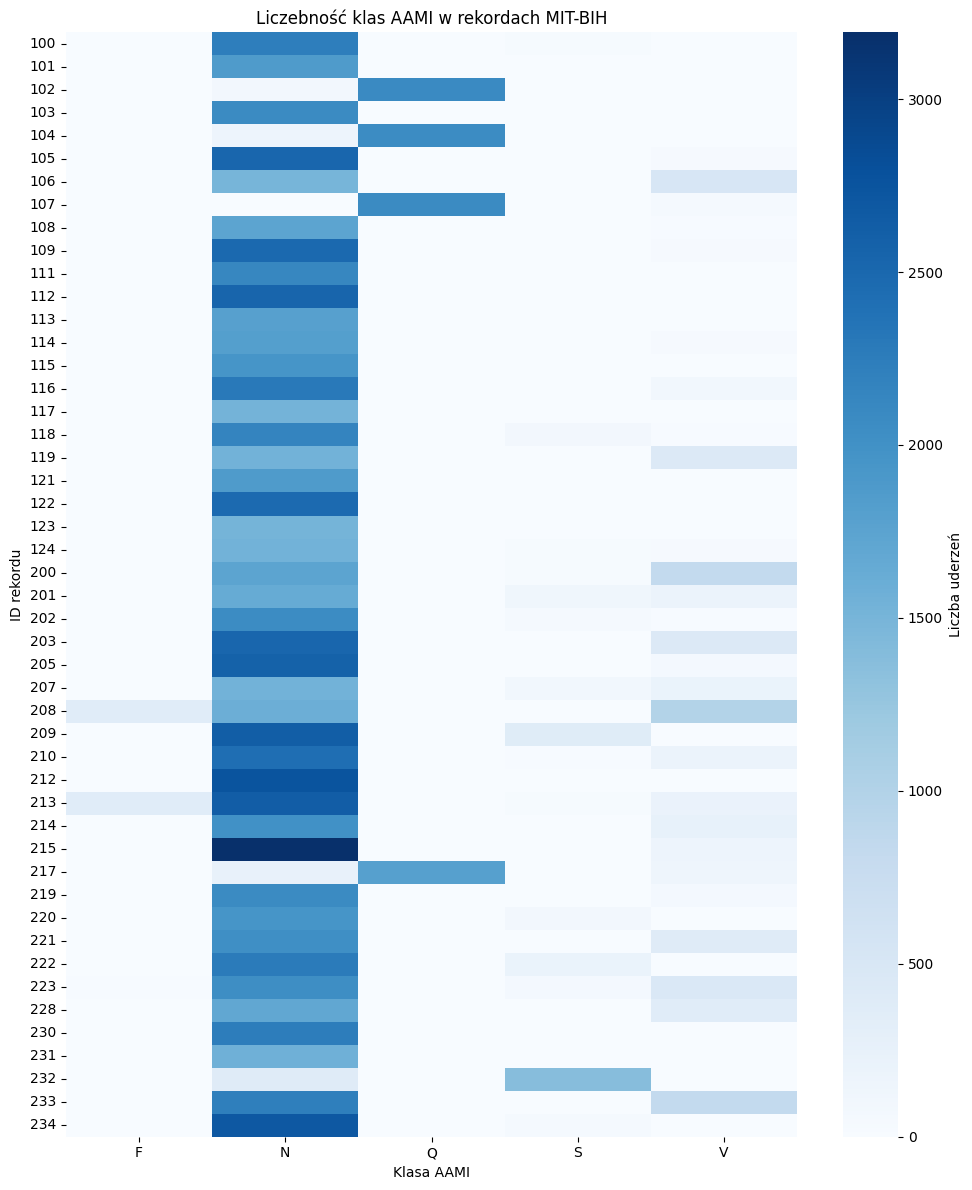

In [15]:
fig, ax = plt.subplots(figsize=(10, 12))

sns.heatmap(
    record_class_counts,
    cmap='Blues',
    ax=ax,
    cbar_kws={'label': 'Liczba uderzeń'}
)

ax.set_title('Liczebność klas AAMI w rekordach MIT-BIH')
ax.set_xlabel('Klasa AAMI')
ax.set_ylabel('ID rekordu')

plt.tight_layout()
plt.show()

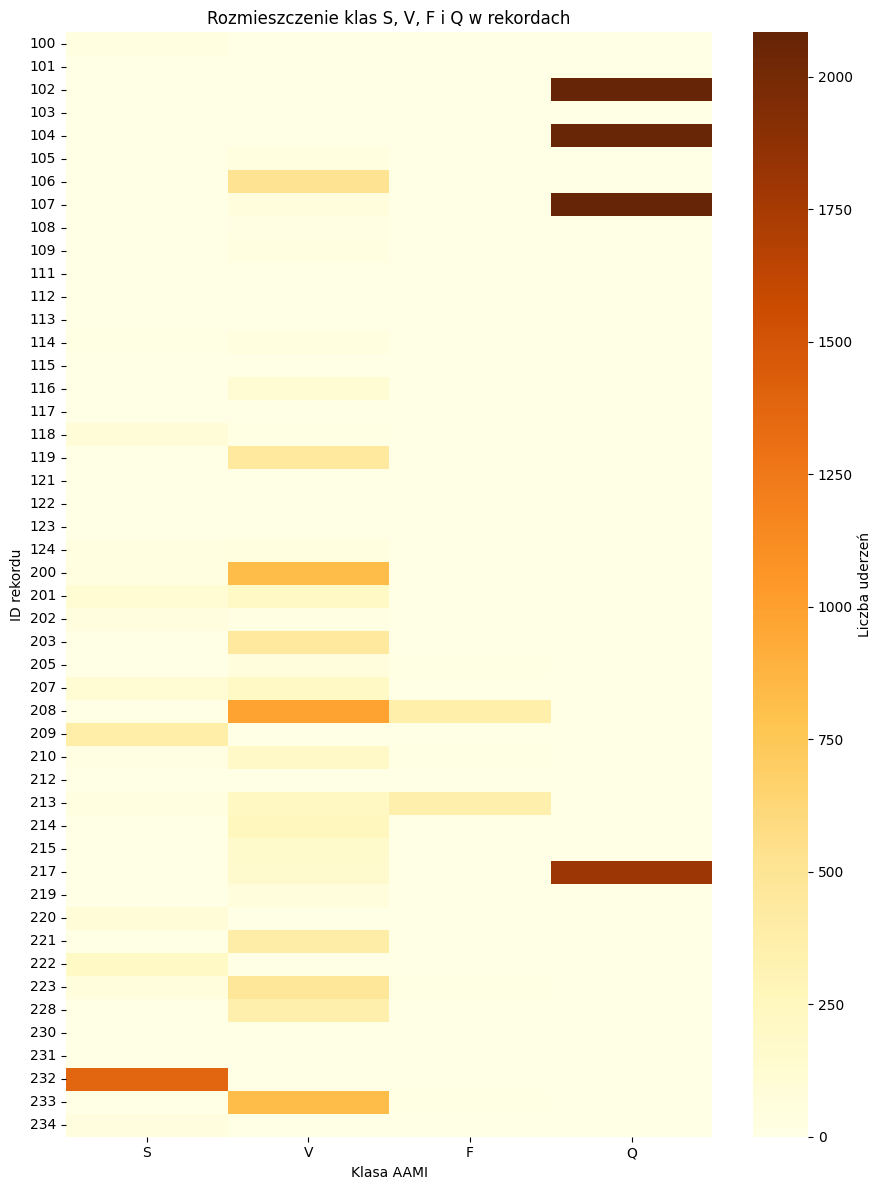

In [16]:
fig, ax = plt.subplots(figsize=(9, 12))

sns.heatmap(
    record_class_counts[minority_classes],
    cmap='YlOrBr',
    ax=ax,
    cbar_kws={'label': 'Liczba uderzeń'}
)

ax.set_title('Rozmieszczenie klas S, V, F i Q w rekordach')
ax.set_xlabel('Klasa AAMI')
ax.set_ylabel('ID rekordu')

plt.tight_layout()
plt.show()

In [17]:
for beat_class in ['F', 'Q']:

    counts = record_class_counts[beat_class]
    counts = counts[counts > 0].sort_values(ascending=False)

    percentages = 100 * counts / counts.sum()

    summary = pd.DataFrame({
        'Liczba uderzeń': counts,
        'Udział w klasie [%]': percentages.round(2)
    })

    print(f'Klasa {beat_class}')
    display(summary)

Klasa F


,Liczba uderzeń,Udział w klasie [%]
record_id,,
208,372,46.38
213,362,45.14
223,14,1.75
233,11,1.37
205,11,1.37
210,10,1.25
124,5,0.62
114,4,0.50
108,2,0.25


Klasa Q


,Liczba uderzeń,Udział w klasie [%]
record_id,,
102,2084,25.92
107,2077,25.83
104,2062,25.65
217,1802,22.41
105,5,0.06
203,4,0.05
101,2,0.02
208,2,0.02
214,2,0.02
